# Knowledge Engineering: Autonomous (Self-Driving) Trailer Agent
**ICS 3202 Artificial Intelligence, Practical Exercise 4 (Aug–Nov 2026)**

Repository: `KnowledgeEngineering` | File: `Autonomous_Trailer.ipynb`

| Group member | Admission no. | Contribution  |
|---|---|---|
| Ivan Wachira | 176830 | Directed graph, distance measures, search tree (Step 4a, 4b, 4d) |
| Caleb Munene | 189719 | Knowledge base, inference rules and explanations (Step 4c, Step 5) |
| Dalton Mule | 184066 | Agent loop, scenarios, debugging and testing (Step 4e, Steps 6 to 9) |

This notebook follows the 10-step knowledge-engineering template used in class and applies it to a **knowledge-based self-driving trailer**. The trailer keeps a **knowledge base (KB)** of the road network (a **directed graph**), **distance measures**, and **if-then rules**. It is told what it perceives (weather, time, load, fuel, hazards), **infers** what is blocked, slow or costly, then **asks** the KB's search machinery (a **search tree**) for the safest, cheapest route.

## Step 1: Identify the Task
The task is to help a heavy trailer decide **where to drive next** so it reaches a destination town safely, with fuel, at minimum effective cost.

**Goal:** make safe, fuel-feasible routing decisions with minimal risk and distance.

**PEAS description**

| | |
|---|---|
| Performance | Reach goal, minimise effective cost (km × risk factor), never run out of fuel, never enter a blocked or unsafe road |
| Environment | Kenyan highway network (directed graph), weather, time of day, hazards, fuel stations |
| Actuators | `drive(a, b)`, `refuel(city)`, `hold` (wait when no safe route exists) |
| Sensors | Weather, time of day, load, fuel level, hazard reports (flood, accident), GPS position |

## Step 2: Assemble Relevant Knowledge
The system needs to know:
* The towns (nodes) and their GPS coordinates
* The roads (directed edges) with length, speed limit, surface and steepness
* Which towns have fuel stations, and the trailer's fuel range
* How weather, time of day, load and hazards change what is safe

**Sources / APIs declaration.** The road network above is a **hand-built, simplified model** of Kenyan highways (distances are approximate and illustrative; every road is at least as long as the straight-line distance so the heuristic stays admissible). Optional live helpers are defined near the end of the notebook: **Open-Meteo** (free, no key, current rain) and the **OSRM public demo server** (driving distance). They are switched **off by default** (`USE_LIVE_APIS = False`) so the notebook runs offline; the code is in this notebook and will be in the same repository.

In [1]:
import math, heapq, itertools
from dataclasses import dataclass
from collections import defaultdict

## Step 3: Define the Vocabulary
* **Constants:** towns (`Nairobi`, `Nakuru`, `Mombasa`, ..), weather (`clear`, `rain`), time (`day`, `night`), load (`heavy`, `light`), surface (`paved`, `gravel`), hazard kinds (`flooded`, `accident`)
* **Predicates (stored as tuples in the KB):**
  * `("road", a, b)`, `("distance", a, b, km)`, `("speed_limit", a, b, kmh)`, `("surface", a, b, type)`, `("steep", a, b)`
  * `("fuel_station", city)`, `("coords", city, lat, lon)`
  * Percepts: `("weather", w)`, `("time", t)`, `("load", l)`, `("hazard", a, b, kind)`
  * Derived: `("blocked", a, b)`, `("cost_factor", a, b, x)`, `("speed_cap", a, b, kmh)`
* **Variables** in rules start with `?` (e.g. `?a`, `?b`).

## Step 4: Encode General Knowledge about the Domain `[3 marks]`
### 4a. The directed graph (roads), coordinates and fuel stations

In [2]:
COORDS = {  # town: (latitude, longitude)
    "Nairobi": (-1.2864, 36.8172), "Thika": (-1.0332, 37.0693), "Machakos": (-1.5177, 37.2634),
    "Mtito Andei": (-2.6930, 38.1660), "Voi": (-3.3961, 38.5561), "Mombasa": (-4.0435, 39.6682),
    "Limuru": (-1.1058, 36.6420), "Naivasha": (-0.7172, 36.4310), "Nakuru": (-0.3031, 36.0800),
    "Eldoret": (0.5143, 35.2698), "Kisumu": (-0.0917, 34.7680), "Nyeri": (-0.4201, 36.9476),
    "Embu": (-0.5388, 37.4596),
}

@dataclass(frozen=True)
class Road:
    src: str; dst: str; km: float; limit: int; surface: str; steep: bool

# a, b, km, speed limit, surface, steep, two_way   (illustrative distances)
ROADS_RAW = [
    ("Nairobi", "Thika", 45, 80, "paved", False, True),
    ("Nairobi", "Machakos", 63, 80, "paved", False, True),
    ("Nairobi", "Mtito Andei", 235, 80, "paved", False, True),
    ("Nairobi", "Limuru", 35, 80, "paved", False, True),
    ("Machakos", "Mtito Andei", 180, 80, "paved", False, True),
    ("Mtito Andei", "Voi", 100, 80, "paved", False, True),
    ("Voi", "Mombasa", 160, 80, "paved", False, True),
    ("Limuru", "Naivasha", 70, 80, "paved", True, True),
    ("Naivasha", "Nakuru", 65, 80, "paved", False, True),
    ("Nakuru", "Eldoret", 155, 80, "paved", False, True),
    ("Nakuru", "Kisumu", 185, 80, "paved", True, True),
    ("Eldoret", "Kisumu", 140, 80, "paved", False, True),
    ("Thika", "Nyeri", 95, 80, "paved", False, True),
    ("Thika", "Embu", 100, 80, "paved", False, True),
    ("Thika", "Machakos", 75, 80, "paved", False, True),
    ("Nyeri", "Embu", 100, 80, "paved", False, True),
    ("Nyeri", "Nakuru", 140, 50, "gravel", True, False),   # ONE-WAY, gravel, steep shortcut
]
GRAPH = defaultdict(list)      # adjacency list of a DIRECTED graph
ROAD_INDEX = {}
def _add(r): GRAPH[r.src].append(r); ROAD_INDEX[(r.src, r.dst)] = r
for a, b, km, lim, surf, steep, two in ROADS_RAW:
    _add(Road(a, b, km, lim, surf, steep))
    if two: _add(Road(b, a, km, lim, surf, steep))

STATIONS = {"Nairobi", "Thika", "Machakos", "Mtito Andei", "Voi", "Mombasa",
            "Naivasha", "Nakuru", "Eldoret", "Kisumu", "Nyeri"}   # no station at Limuru or Embu
TANK_RANGE = 450   # km on a full tank

print(f"{len(COORDS)} towns, {len(ROAD_INDEX)} directed edges, {len(STATIONS)} fuel stations")
for city in ("Nairobi", "Nyeri", "Nakuru"):
    print(f"{city:8} ->", [(r.dst, r.km) for r in GRAPH[city]])

13 towns, 33 directed edges, 11 fuel stations
Nairobi  -> [('Thika', 45), ('Machakos', 63), ('Mtito Andei', 235), ('Limuru', 35)]
Nyeri    -> [('Thika', 95), ('Embu', 100), ('Nakuru', 140)]
Nakuru   -> [('Naivasha', 65), ('Eldoret', 155), ('Kisumu', 185)]


### 4b. Distance measures
Three measures between GPS points. **Haversine** (great-circle) never exceeds road distance, so it is an **admissible and consistent heuristic** for A*. **Manhattan** can overestimate, so it is shown for comparison only.

In [3]:
R_EARTH = 6371.0088
def haversine(a, b):
    (la1, lo1), (la2, lo2) = COORDS[a], COORDS[b]
    p1, p2 = math.radians(la1), math.radians(la2)
    dphi, dl = p2 - p1, math.radians(lo2 - lo1)
    h = math.sin(dphi/2)**2 + math.cos(p1)*math.cos(p2)*math.sin(dl/2)**2
    return 2 * R_EARTH * math.asin(math.sqrt(h))

def _xy(a, b):
    (la1, lo1), (la2, lo2) = COORDS[a], COORDS[b]
    mid = math.radians((la1 + la2) / 2)
    return R_EARTH*math.radians(lo2-lo1)*math.cos(mid), R_EARTH*math.radians(la2-la1)

def euclidean(a, b):
    dx, dy = _xy(a, b); return math.hypot(dx, dy)
def manhattan(a, b):
    dx, dy = _xy(a, b); return abs(dx) + abs(dy)

print(f"{'Pair':24}{'Haversine':>10}{'Euclid.':>9}{'Manhattan':>10}  (km)")
for a, b in [("Nairobi","Mombasa"), ("Nairobi","Kisumu"), ("Nakuru","Eldoret"), ("Thika","Nyeri")]:
    print(f"{a+' - '+b:24}{haversine(a,b):10.0f}{euclidean(a,b):9.0f}{manhattan(a,b):10.0f}")

# Heuristic check: every road must be >= straight-line distance (admissible & consistent)
bad = [(r.src, r.dst) for r in ROAD_INDEX.values() if r.km < haversine(r.src, r.dst)]
print("\nRoads shorter than straight line (should be none):", bad)

Pair                     Haversine  Euclid. Manhattan  (km)
Nairobi - Mombasa              441      441       623
Nairobi - Kisumu               264      264       361
Nakuru - Eldoret               128      128       181
Thika - Nyeri                   70       70        82

Roads shorter than straight line (should be none): []


### 4c. The knowledge base and its inference rules (forward chaining)
Facts are tuples. A rule is `(name, [premises], [conclusions])`; `?x` marks a variable. The engine keeps deriving new facts until nothing new appears, and records **why** each fact was derived so the agent can explain itself.

In [4]:
SINGLE_VALUED = {"weather", "time", "load"}   # a new percept replaces the old one

def is_var(x): return isinstance(x, str) and x.startswith("?")
def match(pattern, fact, b):
    if len(pattern) != len(fact): return None
    b = dict(b)
    for p, f in zip(pattern, fact):
        if is_var(p):
            if p in b and b[p] != f: return None
            b[p] = f
        elif p != f: return None
    return b
def solve(premises, facts, b):
    if not premises: yield b; return
    for f in list(facts):
        nb = match(premises[0], f, b)
        if nb is not None: yield from solve(premises[1:], facts, nb)
def subst(t, b): return tuple(b.get(x, x) if is_var(x) else x for x in t)

RULES = [
    ("R1 flooded road is blocked",   [("hazard","?a","?b","flooded")],  [("blocked","?a","?b"), ("blocked","?b","?a")]),
    ("R2 accident blocks road",      [("hazard","?a","?b","accident")], [("blocked","?a","?b"), ("blocked","?b","?a")]),
    ("R3 rain + gravel is unsafe",   [("weather","rain"), ("surface","?a","?b","gravel")], [("blocked","?a","?b")]),
    ("R4 night + gravel is unsafe",  [("time","night"), ("surface","?a","?b","gravel")],   [("blocked","?a","?b")]),
    ("R5 rain on steep road costs more", [("weather","rain"), ("steep","?a","?b")], [("cost_factor","?a","?b",1.5)]),
    ("R6 heavy load on steep road costs more", [("load","heavy"), ("steep","?a","?b")], [("cost_factor","?a","?b",1.3)]),
    ("R7 rain caps speed at 60",     [("weather","rain"), ("road","?a","?b")],  [("speed_cap","?a","?b",60)]),
    ("R8 night caps speed at 70",    [("time","night"), ("road","?a","?b")],    [("speed_cap","?a","?b",70)]),
]

class KnowledgeBase:
    def __init__(self, rules=RULES):
        self.static, self.percepts, self.derived, self.why, self.rules = set(), set(), set(), {}, list(rules)
    def tell(self, fact, static=False):
        if static: self.static.add(fact); return
        if fact[0] in SINGLE_VALUED:
            self.percepts = {p for p in self.percepts if p[0] != fact[0]}
        self.percepts.add(fact)
    def retract_hazards(self): self.percepts = {p for p in self.percepts if p[0] != "hazard"}
    def infer(self):
        base = self.static | self.percepts
        known, self.why = set(base), {}
        changed = True
        while changed:
            changed = False
            for name, prem, concl in self.rules:
                for b in list(solve(prem, known, {})):
                    for c in concl:
                        f = subst(c, b)
                        if f not in known:
                            known.add(f); self.why[f] = (name, [subst(p, b) for p in prem]); changed = True
        self.derived = known - base
    def all_facts(self): return self.static | self.percepts | self.derived
    def blocked(self): return {(f[1], f[2]) for f in self.derived if f[0] == "blocked"}
    def cost_factors(self):
        out = defaultdict(lambda: 1.0)
        for f in self.derived:
            if f[0] == "cost_factor": out[(f[1], f[2])] *= f[3]
        return out
    def speed(self, a, b):
        caps = [f[3] for f in self.derived if f[0] == "speed_cap" and f[1] == a and f[2] == b]
        return min([ROAD_INDEX[(a, b)].limit] + caps)
    def explain(self, fact, depth=0):
        pad = "   " * depth
        if fact in self.why:
            rule, prem = self.why[fact]; print(f"{pad}{fact}  <-  {rule}")
            for p in prem: self.explain(p, depth + 1)
        else: print(f"{pad}{fact}  (given)")

def build_kb():
    kb = KnowledgeBase()
    for r in ROAD_INDEX.values():
        kb.tell(("road", r.src, r.dst), True); kb.tell(("distance", r.src, r.dst, r.km), True)
        kb.tell(("speed_limit", r.src, r.dst, r.limit), True); kb.tell(("surface", r.src, r.dst, r.surface), True)
        if r.steep: kb.tell(("steep", r.src, r.dst), True)
    for c in STATIONS: kb.tell(("fuel_station", c), True)
    for c, (la, lo) in COORDS.items(): kb.tell(("coords", c, la, lo), True)
    kb.tell(("weather", "clear")); kb.tell(("time", "day")); kb.tell(("load", "heavy"))
    kb.infer(); return kb

KB = build_kb()
print(len(KB.static), "static facts,", len(KB.percepts), "percepts,", len(KB.derived), "derived facts")

161 static facts, 3 percepts, 5 derived facts


### 4d. The search tree
The agent turns "get me from A to B" into a **search tree**: each node holds a state `(town, fuel_left)`, its parent, the action taken and the path cost `g`. Strategies differ only in how the frontier is ordered: **BFS** (FIFO), **DFS** (LIFO), **UCS** (`g`), **Greedy** (`h`), **A\*** (`g + h`, with `h` = haversine distance).

In [5]:
class Node:
    __slots__ = ("state", "parent", "action", "g", "depth")
    def __init__(self, state, parent=None, action=None, g=0.0):
        self.state, self.parent, self.action, self.g = state, parent, action, g
        self.depth = 0 if parent is None else parent.depth + 1
    def solution(self):
        acts, n = [], self
        while n.parent: acts.append(n.action); n = n.parent
        return acts[::-1]

class RouteProblem:
    """State = (town, fuel_km). fuel=None means ignore fuel (plain graph search)."""
    def __init__(self, start, goal, blocked=frozenset(), factor=None, fuel=None,
                 tank=TANK_RANGE, stations=STATIONS, refuel_cost=15):
        self.start, self.goal, self.blocked = start, goal, blocked
        self.factor = factor or {}; self.fuel, self.tank = fuel, tank
        self.stations, self.refuel_cost = stations, refuel_cost
    def initial(self): return (self.start, self.fuel)
    def is_goal(self, s): return s[0] == self.goal
    def h(self, s): return haversine(s[0], self.goal)
    def actions(self, s):
        city, fuel = s
        for r in GRAPH[city]:
            if (city, r.dst) in self.blocked: continue
            if fuel is not None and fuel < r.km: continue
            nf = None if fuel is None else fuel - r.km
            yield ("drive", city, r.dst, r.km), (r.dst, nf), r.km * self.factor.get((city, r.dst), 1.0)
        if fuel is not None and city in self.stations and fuel < self.tank:
            yield ("refuel", city), (city, self.tank), self.refuel_cost

def tree_search(problem, strategy="astar"):
    cnt, frontier, explored = itertools.count(), [], set()
    expanded, children, order = [], {}, {}
    def key(n, c):
        return {"bfs": c, "dfs": -c, "ucs": n.g, "greedy": problem.h(n.state),
                "astar": n.g + problem.h(n.state)}[strategy]
    root = Node(problem.initial()); generated = 1
    heapq.heappush(frontier, (key(root, 0), next(cnt), root))
    while frontier:
        _, _, n = heapq.heappop(frontier)
        if n.state in explored: continue
        explored.add(n.state); expanded.append(n.state[0]); order[id(n)] = len(expanded)
        if problem.is_goal(n.state):
            return dict(node=n, plan=n.solution(), cost=n.g, expanded=expanded, generated=generated,
                        root=root, children=children, order=order)
        kids = []
        for act, s2, c in problem.actions(n.state):
            ch = Node(s2, n, act, n.g + c); kids.append(ch); generated += 1
            heapq.heappush(frontier, (key(ch, next(cnt)), next(cnt), ch))
        children[id(n)] = kids
    return None

def print_search_tree(res, max_depth=3):
    def rec(n, pad, d):
        tag = f"#{res['order'][id(n)]}" if id(n) in res["order"] else "frontier"
        fuel = "" if n.state[1] is None else f", fuel={n.state[1]:.0f}"
        print(f"{pad}{n.state[0]} (g={n.g:.0f}{fuel}) [{tag}]")
        if d < max_depth:
            for ch in res["children"].get(id(n), []): rec(ch, pad + "    ", d + 1)
    rec(res["root"], "", 0)

# Compare strategies on the plain graph (no fuel, no hazards)
print(f"{'Strategy':8}{'Cost km':>8}{'Expanded':>10}{'Generated':>11}  Route")
for strat in ("bfs", "dfs", "ucs", "greedy", "astar"):
    res = tree_search(RouteProblem("Nairobi", "Kisumu"), strat)
    route = ["Nairobi"] + [a[2] for a in res["plan"]]
    print(f"{strat:8}{res['cost']:8.0f}{len(res['expanded']):10}{res['generated']:11}  {' > '.join(route)}")

print("\nA* search tree (Nairobi to Kisumu), # = order of expansion:")
print_search_tree(tree_search(RouteProblem("Nairobi", "Kisumu"), "astar"), max_depth=3)

Strategy Cost km  Expanded  Generated  Route
bfs          465        13         32  Nairobi > Thika > Nyeri > Nakuru > Kisumu
dfs          355         5         12  Nairobi > Limuru > Naivasha > Nakuru > Kisumu
ucs          355        12         31  Nairobi > Limuru > Naivasha > Nakuru > Kisumu
greedy       355         5         12  Nairobi > Limuru > Naivasha > Nakuru > Kisumu
astar        355         6         16  Nairobi > Limuru > Naivasha > Nakuru > Kisumu

A* search tree (Nairobi to Kisumu), # = order of expansion:
Nairobi (g=0) [#1]
    Thika (g=45) [#5]
        Nairobi (g=90) [frontier]
        Nyeri (g=140) [frontier]
        Embu (g=145) [frontier]
        Machakos (g=120) [frontier]
    Machakos (g=63) [frontier]
    Mtito Andei (g=235) [frontier]
    Limuru (g=35) [#2]
        Nairobi (g=70) [frontier]
        Naivasha (g=105) [#3]
            Limuru (g=175) [frontier]
            Nakuru (g=170) [#4]


### 4e. The knowledge-based agent (TELL, ASK, ACT)
The agent **TELLs** the KB what it perceives, runs **inference**, **ASKs** the search for a plan using only the KB's conclusions (blocked roads, cost factors), then drives. When a new percept arrives mid-trip it **re-plans** from where it is.

In [6]:
class TrailerAgent:
    def __init__(self, kb, tank=TANK_RANGE):
        self.kb, self.tank, self.last = kb, tank, None
    def tell(self, facts):
        for f in facts: self.kb.tell(f)
        self.kb.infer()
    def set_conditions(self, weather=None, time=None, load=None):
        self.tell([(k, v) for k, v in (("weather", weather), ("time", time), ("load", load)) if v])
    def plan(self, city, goal, fuel, strategy="astar"):
        p = RouteProblem(city, goal, frozenset(self.kb.blocked()), dict(self.kb.cost_factors()),
                         fuel=fuel, tank=self.tank)
        self.last = tree_search(p, strategy)
        return None if self.last is None else self.last["plan"]
    def drive(self, start, goal, fuel=None, events=None, verbose=True):
        events, fuel = dict(events or {}), (self.tank if fuel is None else fuel)
        say = print if verbose else (lambda *a: None)
        city, km_total, hours, stops = start, 0, 0.0, []
        if city in events: self.tell(events.pop(city)); say(f"[percept at {city}] new facts told to KB")
        plan = self.plan(city, goal, fuel)
        say(f"Initial plan: {self.describe(plan)}")
        while city != goal:
            if plan is None:
                say(f"!! NO SAFE ROUTE from {city} to {goal}: trailer HOLDS position.")
                return dict(ok=False, at=city, km=km_total, hours=hours, stops=stops)
            act = plan.pop(0)
            if act[0] == "refuel":
                fuel = self.tank; stops.append(act[1]); say(f"   REFUEL at {act[1]} (tank full: {fuel} km)"); continue
            _, a, b, km = act
            sp = self.kb.speed(a, b); hours += km / sp; km_total += km; fuel -= km; city = b
            say(f"   DRIVE {a} -> {b}: {km} km at {sp} km/h, fuel left {fuel:.0f} km")
            if city in events:
                self.tell(events.pop(city)); say(f"[percept at {city}] new facts told to KB; re-planning")
                new = self.plan(city, goal, fuel)
                if new != plan: say(f"   REPLAN: {self.describe(new)}")
                plan = new
        say(f"ARRIVED at {goal}: {km_total} km, about {hours:.1f} h, refuel stops: {stops or 'none'}")
        return dict(ok=True, at=city, km=km_total, hours=hours, stops=stops)
    @staticmethod
    def describe(plan):
        if plan is None: return "no route"
        return " > ".join(a[2] if a[0] == "drive" else f"[refuel {a[1]}]" for a in plan) or "already there"

## Step 5: Add New Facts to the Knowledge Base
Knowledge can be extended **without user input** (functions below) or **interactively** (`add_fact_interactive`). New facts are added to the live graph and KB, and inference is re-run.

In [7]:
def show_kb(kind=None):
    print("\n--- Current Knowledge Base ---")
    for f in sorted(KB.all_facts(), key=str):
        if kind is None or f[0] == kind: print(f)
    print("------------------------------")

def add_road(a, b, km, limit=80, surface="paved", steep=False, two_way=True):
    """Add a new road (directed edge) to the graph and KB."""
    for x in (a, b):
        if x not in COORDS: raise ValueError(f"Unknown town '{x}': add_town() first")
    if km < haversine(a, b): raise ValueError(f"{km} km is shorter than straight line {haversine(a,b):.0f} km")
    pairs = [(a, b), (b, a)] if two_way else [(a, b)]
    for s, d in pairs:
        r = Road(s, d, km, limit, surface, steep); _add(r)
        KB.tell(("road", s, d), True); KB.tell(("distance", s, d, km), True)
        KB.tell(("speed_limit", s, d, limit), True); KB.tell(("surface", s, d, surface), True)
        if steep: KB.tell(("steep", s, d), True)
    KB.infer(); print(f"Added road {a} {'<->' if two_way else '->'} {b} ({km} km, {surface})")

def add_town(name, lat, lon, fuel_station=False):
    COORDS[name] = (lat, lon); KB.tell(("coords", name, lat, lon), True)
    if fuel_station: STATIONS.add(name); KB.tell(("fuel_station", name), True)
    KB.infer(); print(f"Added town {name} (fuel station: {fuel_station})")

def add_hazard(a, b, kind):
    AGENT.tell([("hazard", a, b, kind)]); print(f"Hazard told to KB: {kind} on {a}-{b}")

def add_rule(name, premises, conclusions):
    KB.rules.append((name, premises, conclusions)); KB.infer(); print(f"Added rule: {name}")

def add_fact_interactive():
    """Ask the user for a new road, like add_fact() in the traffic-light example."""
    a = input("From town: ").strip().title(); b = input("To town: ").strip().title()
    km = float(input("Distance (km): ")); surf = input("Surface (paved/gravel): ").strip().lower() or "paved"
    add_road(a, b, km, surface=surf)

AGENT = TrailerAgent(KB)

# Example of adding knowledge (no user input)
add_town("Kitui", -1.3667, 38.0106, fuel_station=True)
add_road("Machakos", "Kitui", 85, 80, "paved")
add_road("Kitui", "Mtito Andei", 150, 60, "gravel")
add_rule("R9 gravel road in the dark is slow (cost x1.4)",
         [("time", "night"), ("surface", "?a", "?b", "gravel")], [("cost_factor", "?a", "?b", 1.4)])
# add_fact_interactive()     # <- uncomment to type in a road yourself
show_kb("fuel_station")

Added town Kitui (fuel station: True)
Added road Machakos <-> Kitui (85 km, paved)
Added road Kitui <-> Mtito Andei (150 km, gravel)
Added rule: R9 gravel road in the dark is slow (cost x1.4)

--- Current Knowledge Base ---
('fuel_station', 'Eldoret')
('fuel_station', 'Kisumu')
('fuel_station', 'Kitui')
('fuel_station', 'Machakos')
('fuel_station', 'Mombasa')
('fuel_station', 'Mtito Andei')
('fuel_station', 'Nairobi')
('fuel_station', 'Naivasha')
('fuel_station', 'Nakuru')
('fuel_station', 'Nyeri')
('fuel_station', 'Thika')
('fuel_station', 'Voi')
------------------------------


## Steps 6 & 7: Encode a Specific Problem Instance (Facts) & Pose Queries and Get Answers `[3 marks]`
**Instance:** a heavy trailer in Nairobi, clear weather by day, 300 km of fuel, must reach Mombasa (495 km, more than its fuel range, so a refuel stop is needed).

In [8]:
# Step 6: the current observations (percepts)
AGENT.set_conditions(weather="clear", time="day", load="heavy")
start, goal, fuel_now = "Nairobi", "Mombasa", 300

# Step 7: the agent queries the KB / search tree
print("=== Autonomous Trailer Decision System ===")
print(f"Observation: at {start}, goal {goal}, fuel {fuel_now} km, weather clear, day, heavy load")
trip = AGENT.drive(start, goal, fuel=fuel_now)

=== Autonomous Trailer Decision System ===
Observation: at Nairobi, goal Mombasa, fuel 300 km, weather clear, day, heavy load
Initial plan: Mtito Andei > [refuel Mtito Andei] > Voi > Mombasa
   DRIVE Nairobi -> Mtito Andei: 235 km at 80 km/h, fuel left 65 km
   REFUEL at Mtito Andei (tank full: 450 km)
   DRIVE Mtito Andei -> Voi: 100 km at 80 km/h, fuel left 350 km
   DRIVE Voi -> Mombasa: 160 km at 80 km/h, fuel left 190 km
ARRIVED at Mombasa: 495 km, about 6.2 h, refuel stops: ['Mtito Andei']


## Step 8: Querying the Knowledge Base
Different questions, same KB. Each scenario changes the percepts, which changes what the rules derive and therefore the route.

In [9]:
print("Q1. Nyeri to Nakuru in clear weather (gravel shortcut allowed):")
AGENT.set_conditions(weather="clear", time="day", load="heavy"); AGENT.drive("Nyeri", "Nakuru")

print("\nQ2. Same trip when it RAINS (R3 blocks gravel, R7 caps speed at 60):")
AGENT.set_conditions(weather="rain"); AGENT.drive("Nyeri", "Nakuru")
print("\nWhy is the Nyeri-Nakuru road blocked?"); KB.explain(("blocked", "Nyeri", "Nakuru"))

print("\nQ3. Low fuel (100 km): Nairobi to Nakuru. Limuru has no station, so refuel first:")
AGENT.set_conditions(weather="clear"); AGENT.drive("Nairobi", "Nakuru", fuel=100)

print("\nQ4. Dynamic hazard: Nairobi to Kisumu, flood reported on Nakuru-Kisumu once at Nakuru:")
AGENT.drive("Nairobi", "Kisumu", events={"Nakuru": [("hazard", "Nakuru", "Kisumu", "flooded")]})
KB.retract_hazards(); KB.infer()

print("\nQ5. Accident on Mtito Andei-Voi (the only way to Mombasa):")
AGENT.tell([("hazard", "Mtito Andei", "Voi", "accident")]); AGENT.drive("Nairobi", "Mombasa")
KB.retract_hazards(); KB.infer()

Q1. Nyeri to Nakuru in clear weather (gravel shortcut allowed):
Initial plan: Nakuru
   DRIVE Nyeri -> Nakuru: 140 km at 50 km/h, fuel left 310 km
ARRIVED at Nakuru: 140 km, about 2.8 h, refuel stops: none

Q2. Same trip when it RAINS (R3 blocks gravel, R7 caps speed at 60):
Initial plan: Thika > Nairobi > Limuru > Naivasha > Nakuru
   DRIVE Nyeri -> Thika: 95 km at 60 km/h, fuel left 355 km
   DRIVE Thika -> Nairobi: 45 km at 60 km/h, fuel left 310 km
   DRIVE Nairobi -> Limuru: 35 km at 60 km/h, fuel left 275 km
   DRIVE Limuru -> Naivasha: 70 km at 60 km/h, fuel left 205 km
   DRIVE Naivasha -> Nakuru: 65 km at 60 km/h, fuel left 140 km
ARRIVED at Nakuru: 310 km, about 5.2 h, refuel stops: none

Why is the Nyeri-Nakuru road blocked?
('blocked', 'Nyeri', 'Nakuru')  <-  R3 rain + gravel is unsafe
   ('weather', 'rain')  (given)
   ('surface', 'Nyeri', 'Nakuru', 'gravel')  (given)

Q3. Low fuel (100 km): Nairobi to Nakuru. Limuru has no station, so refuel first:
Initial plan: [refuel N

## Step 9: Debugging the Knowledge Base
Faulty or unusual inputs: unknown towns, impossible fuel, same start and goal, roads shorter than physically possible, night driving on gravel.

In [10]:
def safe_query(start, goal, fuel=None):
    if start not in COORDS or goal not in COORDS:
        return f"Unknown town ('{start}' / '{goal}'): ask operator, do not move."
    res = AGENT.drive(start, goal, fuel=fuel, verbose=False)
    return (f"OK {res['km']} km, ~{res['hours']:.1f} h, refuels {res['stops'] or 'none'}"
            if res["ok"] else f"No safe route, holding at {res['at']}")

AGENT.set_conditions(weather="clear", time="day", load="heavy"); KB.retract_hazards(); KB.infer()
tests = [("Nairobi","Mombasa",450), ("Nairobi","Nairobi",450), ("Nairobi","Timbuktu",450),
         ("Embu","Nakuru",450), ("Nairobi","Mombasa",30), ("Nairobi","Eldoret",0)]
print("--- Debugging the Knowledge Base ---")
for s, g, f in tests: print(f"{s:8} -> {g:9} fuel={f:3}: {safe_query(s, g, f)}")

try: add_road("Nairobi", "Thika", 10)            # physically impossible
except ValueError as e: print("Rejected bad fact:", e)

AGENT.set_conditions(time="night"); print("\nNight, Nyeri -> Nakuru:", safe_query("Nyeri", "Nakuru"))
AGENT.set_conditions(time="day")

--- Debugging the Knowledge Base ---
Nairobi  -> Mombasa   fuel=450: OK 495 km, ~6.2 h, refuels ['Mtito Andei']
Nairobi  -> Nairobi   fuel=450: OK 0 km, ~0.0 h, refuels none
Nairobi  -> Timbuktu  fuel=450: Unknown town ('Nairobi' / 'Timbuktu'): ask operator, do not move.
Embu     -> Nakuru    fuel=450: OK 240 km, ~4.0 h, refuels none
Nairobi  -> Mombasa   fuel= 30: OK 495 km, ~6.2 h, refuels ['Nairobi', 'Mtito Andei']
Nairobi  -> Eldoret   fuel=  0: OK 325 km, ~4.1 h, refuels ['Nairobi']
Rejected bad fact: 10 km is shorter than straight line 40 km

Night, Nyeri -> Nakuru: OK 310 km, ~4.4 h, refuels none


### Visualising the directed graph and the chosen route

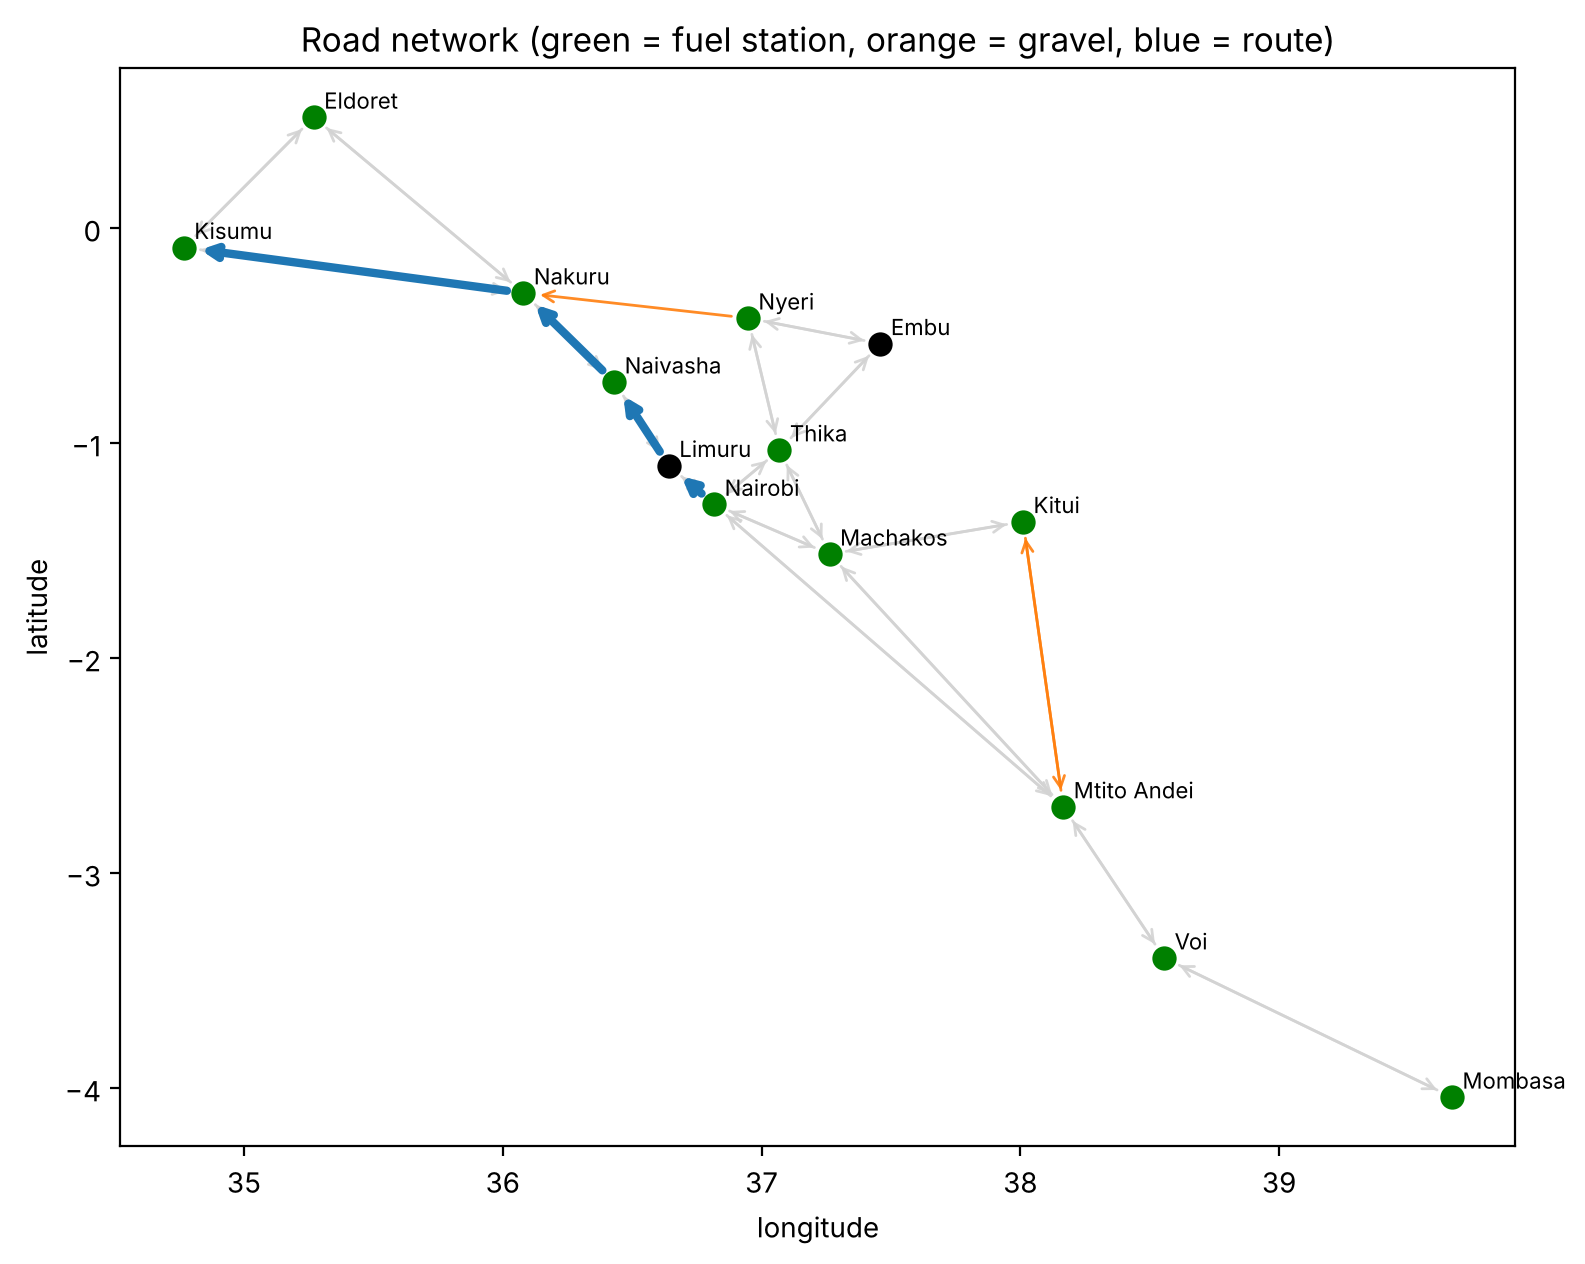

In [11]:
import matplotlib
import matplotlib.pyplot as plt
def plot_network(route=None, blocked=()):
    fig, ax = plt.subplots(figsize=(9, 7))
    for r in ROAD_INDEX.values():
        (la1, lo1), (la2, lo2) = COORDS[r.src], COORDS[r.dst]
        col = "red" if (r.src, r.dst) in blocked else ("tab:orange" if r.surface == "gravel" else "lightgray")
        ax.annotate("", xy=(lo2, la2), xytext=(lo1, la1),
                    arrowprops=dict(arrowstyle="->", color=col, lw=1, shrinkA=6, shrinkB=6, alpha=.9))
    if route:
        for a, b in zip(route, route[1:]):
            (la1, lo1), (la2, lo2) = COORDS[a], COORDS[b]
            ax.annotate("", xy=(lo2, la2), xytext=(lo1, la1),
                        arrowprops=dict(arrowstyle="->", color="tab:blue", lw=3, shrinkA=6, shrinkB=6))
    for c, (la, lo) in COORDS.items():
        ax.scatter(lo, la, s=60, c="green" if c in STATIONS else "black", zorder=3); ax.text(lo + .04, la + .04, c, fontsize=8)
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_title("Road network (green = fuel station, orange = gravel, blue = route)"); plt.show()

AGENT.set_conditions(weather="clear", time="day")
p = AGENT.plan("Nairobi", "Kisumu", 450)
plot_network(["Nairobi"] + [a[2] for a in p if a[0] == "drive"], KB.blocked())

## Step 10: Final Reflection
**What worked.** Separating *knowledge* (facts and rules) from *reasoning* (forward chaining and search) made the agent easy to extend: adding a town, a road or a rule changed its behaviour without touching the search code. The directed graph handled one-way roads, the haversine heuristic let A* expand far fewer nodes than BFS or DFS while still returning the optimal route, and the `why` records let the agent **explain** its decisions (e.g. why a road is blocked).

**Challenges.**
* Keeping the heuristic admissible: it only holds if every road is at least as long as the straight line, so `add_road` rejects impossible distances. Manhattan distance can overestimate and would break A*'s optimality.
* Adding fuel to the state made the search space larger, and refuel stops had to be modelled as actions with a cost.
* Re-planning mid-trip: percepts arrive after planning, so the agent must re-run inference and search from its current town and fuel, and it must handle the case where **no** safe route exists (it holds position).
* The knowledge is hand-written and simplified: distances are approximate, risk factors (×1.3, ×1.5) are assumptions, and the rules cannot express uncertainty.

